# ĐỒ ÁN COMPUTER VISION (VN-ALPR) — LPRNET v3
## Biển 2 dòng: mỗi dòng 94×24 (đầu vào 188×24) + Transfer 100% trọng số LPRNet gốc + Phân tích lỗi trên tập Test

**Thay đổi của v3 so với v2 (và lý do):**

| Vấn đề ở v2 | Cách xử lý ở v3 |
| :--- | :--- |
| Biển 2 dòng ghép 2 nửa vào chung 94×24, mỗi dòng chỉ còn 47 px và khoảng **9 bước CTC**. Dòng dưới có 5 chữ số, thêm dấu chấm, lại cần blank chen giữa các số lặp, nên mô hình **mất ký tự**, nhất là số lặp (`99→9`, `555→55`). Xe máy kẹt ở ~64% | Mỗi dòng được resize riêng về **94×24 như một biển 1 dòng** rồi ghép ngang thành **188×24**. Đầu ra tăng từ 18 lên **42 bước** (khoảng 21 bước mỗi dòng). Biển 1 dòng vẫn giữ 94×24 |
| Global Context dùng avgpool kích thước cố định, chỉ chạy được với ảnh rộng 94 | Giữ nguyên avgpool gốc (cùng tỉ lệ cửa sổ), sau đó **nội suy về đúng độ rộng đầu ra** nếu cần. Với ảnh 94 kết quả **giống hệt** bản gốc, nên vẫn transfer 100% |
| Một batch không thể chứa ảnh khác chiều rộng | **Batch theo nhóm**: mỗi batch chỉ có ảnh 94 hoặc chỉ có ảnh 188, thứ tự các batch được xáo. Vẫn lấy mẫu xe máy ×2.5 |
| Augmentation chồng nhiều phép làm xấu ảnh (tối + mờ + giảm phân giải + JPEG), sinh ra mẫu mắt người cũng không đọc được, thành nhiễu nhãn | Thu hẹp biên độ sáng/tối. **Mỗi ảnh tối đa 1 phép làm suy giảm** (mờ / phân giải thấp / JPEG). Nếu ảnh sau augmentation mất quá nửa độ tương phản thì dùng lại ảnh chưa làm xấu |

**Những gì v2 đã thay đổi so với notebook cũ (vẫn giữ nguyên ở v3):**

| Vấn đề ở bản cũ | Cách xử lý ở bản v2 |
| :--- | :--- |
| Kiến trúc tự viết khác bản gốc nên chỉ nạp được **8/47** tensor, thực chất là train từ đầu | Dùng **đúng kiến trúc sirius-ai/LPRNet_Pytorch** (có Global Context, SmallBasicBlock không residual) nên nạp được **100%** trọng số. 3 tầng phụ thuộc số lớp được **cắt theo ký tự chung** (0–9, chữ Latinh) thay vì khởi tạo ngẫu nhiên |
| Không crop khi bbox rộng gần bằng ảnh, rồi heuristic `h/w > 0.65` **cắt đôi cả ảnh toàn cảnh** (ra lưới tản nhiệt + mặt đường) | Luôn crop theo bbox (có đệm). Chỉ cắt đôi khi nhãn là biển 2 dòng |
| Cắt đôi đúng `h/2`, mất hoặc lặp ký tự ở chỗ nối hai dòng | Cắt đôi **chồng lấn 5%** |
| `cv2.imread` tự xoay ảnh theo EXIF nên lệch với bbox | Đọc theo pixel gốc, kiểm tra bbox nằm trong ảnh, xem trực quan các ảnh có cờ EXIF |
| Ký tự ngoài bảng bị **xóa khỏi nhãn** (nhãn bị ngắn đi) | `O→0`, `I→1`. Ký tự lạ khác thì bỏ cả mẫu. Kiểm tra định dạng biển VN |
| Augmentation chỉ chỉnh sáng/tối | Lệch bbox (mô phỏng YOLO), xoay/nghiêng, phối cảnh, mờ, nhiễu, JPEG, độ phân giải thấp. **Không lật ảnh** |
| Xe máy chỉ chiếm ~15% dữ liệu | Lấy mẫu lặp xe máy ×2.5 (`WeightedRandomSampler`) |
| LR 1e-4 + Cosine về 0 sau 40 epoch, loss vẫn còn giảm (chưa hội tụ) | Pha 1: 3 epoch đóng băng. Pha 2: 80 epoch AdamW + OneCycleLR (max 1e-3) |
| Đo FPS không đồng bộ GPU | Có `torch.cuda.synchronize()`, đo thêm thời gian tiền xử lý |

**Cách chạy:** Runtime GPU, sau đó *Run all*. Kết quả lưu vào `TGMT/lprnet_v3/`, không đụng tới `lprnet_v2/`.
- `WEIGHTS_MODE = "author"` (mặc định): transfer từ trọng số tác giả, số liệu sạch cho báo cáo. `"v2"`: khởi tạo từ checkpoint tốt nhất của v2.
- Bước 7 in ảnh trước/sau tiền xử lý. Bước 7.2 **tự dừng** nếu phát hiện nhiều ảnh đầu vào bị trơn hoặc hỏng.
- Colab bị ngắt giữa chừng: đặt `WEIGHTS_MODE = "resume"` ở Bước 1 rồi *Run all*, notebook train tiếp từ epoch cuối.
- Chỉ muốn đánh giá lại: chạy Bước 1 đến 10, rồi nhảy tới Bước 13.

In [1]:
# 0. Cài thư viện (opencv, torch, matplotlib đã có sẵn trên Colab)
!pip install -q editdistance

### 1. Cấu Hình Chung (chỉ cần chỉnh ở ô này)

In [2]:
# ==============================================================================
# BƯỚC 1: CẤU HÌNH CHUNG
# ==============================================================================
import os, re, json, time, random, shutil, traceback
from collections import Counter, defaultdict

import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
import editdistance

# --- Đường dẫn ---
DRIVE_DIR      = "/content/drive/MyDrive/TGMT"
ZIP_PATH       = f"{DRIVE_DIR}/VNLP_detection.zip"
DATASET_DIR    = "/content/dataset"
LOCAL_DIR      = "/content/weights"
SAVE_DIR       = f"{DRIVE_DIR}/lprnet_v3"          # thư mục mới, KHÔNG ghi đè kết quả v2
AUTHOR_WEIGHTS = f"{LOCAL_DIR}/Final_LPRNet_model.pth"
V2_BEST_PATH   = f"{DRIVE_DIR}/lprnet_v2/best_lprnet_vn_v2.pth"
BEST_PATH      = f"{SAVE_DIR}/best_lprnet_vn_v3.pth"
LAST_PATH      = f"{SAVE_DIR}/last_lprnet_vn_v3.pth"

# --- Chế độ trọng số ---
# "author": transfer learning từ Final_LPRNet_model.pth của tác giả (chạy lần đầu, số liệu sạch cho báo cáo)
# "v2"    : khởi tạo từ checkpoint tốt nhất của v2 (cùng kiến trúc, hội tụ nhanh hơn)
# "resume": train tiếp từ LAST_PATH trên Drive (khi Colab bị ngắt giữa chừng)
WEIGHTS_MODE = "author"

# --- Tiền xử lý ---
IMG_W, IMG_H        = 94, 24     # kích thước của MỘT dòng (đúng kích thước đầu vào LPRNet gốc)
IMG_W2              = 2 * IMG_W  # biển 2 dòng: dòng trên | dòng dưới, mỗi dòng 94x24 -> 188x24
PAD_X, PAD_Y        = 0.03, 0.06 # đệm quanh bbox khi đánh giá / suy luận (tỉ lệ theo kích thước bbox)
SPLIT_OVERLAP       = 0.05       # chồng lấn khi cắt đôi biển 2 dòng
EXIF_MODE           = "ignore"   # "ignore": đọc theo pixel gốc | "apply": xoay ảnh theo cờ EXIF
DROP_INVALID_LABELS = True       # bỏ các nhãn không đúng định dạng biển số VN

# --- Huấn luyện ---
SEED            = 42
BATCH_SIZE      = 128
NUM_WORKERS     = min(8, os.cpu_count() or 2)
MOTO_WEIGHT     = 2.5   # hệ số lấy mẫu lặp cho biển xe máy
FROZEN_EPOCHS   = 3     # Pha 1: chỉ train các tầng phụ thuộc số lớp (số liệu "Frozen" cho TN-OCR 1)
FINETUNE_EPOCHS = 80    # Pha 2: fine-tune toàn mạng
LR_HEAD         = 1e-3
MAX_LR          = 1e-3
WEIGHT_DECAY    = 1e-4
DROPOUT         = 0.3

# --- Tự ngắt Colab khi rảnh ---
ENABLE_AUTO_DISCONNECT = True
IDLE_TIMEOUT_MINUTES   = 30

os.makedirs(LOCAL_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
cv2.setNumThreads(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("-> Thiết bị:", device, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

def idle_shutdown_timer(timeout_minutes=IDLE_TIMEOUT_MINUTES):
    if not ENABLE_AUTO_DISCONNECT:
        print("-> Cơ chế tự động ngắt phiên đang TẮT.")
        return
    from google.colab import runtime
    total_seconds = int(timeout_minutes * 60)
    print()
    print("=" * 76)
    print(f"⏰ KÍCH HOẠT HẸN GIỜ TỰ ĐỘNG NGẮT PHIÊN (IDLE SHUTDOWN): {timeout_minutes} PHÚT")
    print("👉 BẤM NÚT DỪNG (STOP Ở CELL NÀY) BẤT KỲ LÚC NÀO ĐỂ HỦY NGẮT VÀ TIẾP TỤC LÀM VIỆC!")
    print("=" * 76)
    try:
        start_time = time.time()
        while True:
            remaining = total_seconds - (time.time() - start_time)
            if remaining <= 0:
                break
            print(f"\r⏳ Thời gian chờ còn lại trước khi ngắt GPU: {int(remaining // 60):02d} phút {int(remaining % 60):02d} giây...", end="", flush=True)
            time.sleep(5)
        print()
        print(f"-> ĐÃ HẾT {timeout_minutes} PHÚT! Đang giải phóng GPU Colab...")
        time.sleep(5)
        runtime.unassign()
    except KeyboardInterrupt:
        print()
        print("* ĐÃ HỦY LỆNH NGẮT PHIÊN THÀNH CÔNG! Giữ nguyên phiên Colab để tiếp tục làm việc. *")

-> Thiết bị: cuda | NVIDIA A100-SXM4-40GB


### 2. Kết Nối Google Drive & Giải Nén Dữ Liệu

In [3]:
from google.colab import drive
drive.mount('/content/drive')
os.makedirs(SAVE_DIR, exist_ok=True)

if not os.path.exists(f"{DATASET_DIR}/detection"):
    os.makedirs(DATASET_DIR, exist_ok=True)
    !unzip -q "{ZIP_PATH}" -d "{DATASET_DIR}"
print("Cấu trúc thư mục tại", DATASET_DIR, ":", os.listdir(DATASET_DIR))

Mounted at /content/drive
Cấu trúc thư mục tại /content/dataset : ['detection']


### 3. Parser Dữ Liệu VNLP
Tên file: `ID1_ID2_ROWTYPE_LABEL_XMIN_YMIN_XMAX_YMAX.jpg` (`ROWTYPE`: `1` = 1 dòng, `0` = 2 dòng).

Khác bản cũ: ký tự ngoài bảng **không còn bị xóa âm thầm khỏi nhãn**. `O→0`, `I→1` (biển VN không dùng chữ O, I). Gặp ký tự lạ khác thì bỏ cả mẫu.

In [4]:
# Bảng ký tự biển số VN: 30 ký tự + 1 blank cho CTC (31 lớp)
CHARS = [
    '0', '1', '2', '3', '4', '5', '6', '7', '8', '9',
    'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'K', 'L', 'M',
    'N', 'P', 'S', 'T', 'U', 'V', 'X', 'Y', 'Z'
]
CHARS_DICT  = {c: i for i, c in enumerate(CHARS)}
BLANK_IDX   = len(CHARS)
NUM_CLASSES = len(CHARS) + 1
GROUPS      = ["1 dòng", "2 dòng ô tô", "xe máy"]
LABEL_FIX   = {"O": "0", "I": "1"}
parse_stats = Counter()

def parse_vnlp_file(txt_path, group, base_dir=DATASET_DIR):
    samples = []
    if not os.path.exists(txt_path):
        print(f"Không tìm thấy file: {txt_path}")
        return samples
    with open(txt_path, "r", encoding="utf-8") as f:
        for line in f:
            rel_path = line.strip()
            if not rel_path:
                continue
            clean_rel = rel_path.lstrip("/")
            full_path = os.path.join(base_dir, clean_rel)
            if not os.path.exists(full_path):
                alt_path = os.path.join(base_dir, clean_rel.replace("detection/", ""))
                if os.path.exists(alt_path):
                    full_path = alt_path

            tokens = os.path.splitext(os.path.basename(rel_path))[0].split("_")
            if len(tokens) < 8:
                parse_stats["tên file sai định dạng"] += 1
                continue
            try:
                xmin, ymin, xmax, ymax = map(int, tokens[4:8])
            except ValueError:
                parse_stats["bbox không phải số"] += 1
                continue
            raw = tokens[3].upper()
            label = "".join(LABEL_FIX.get(c, c) for c in raw)
            if label != raw:
                parse_stats["nhãn được sửa O→0 / I→1"] += 1
            if any(c not in CHARS_DICT for c in label):
                parse_stats["nhãn có ký tự ngoài bảng (bỏ mẫu)"] += 1
                continue
            samples.append({
                "img_path": full_path,
                "label": label,
                "group": group,
                "is_two_rows": tokens[2] == "0",
                "bbox": (xmin, ymin, xmax, ymax),
            })
    return samples

txt_root = f"{DATASET_DIR}/detection" if os.path.exists(f"{DATASET_DIR}/detection") else DATASET_DIR
all_samples = (parse_vnlp_file(f"{txt_root}/list_one_row.txt", "1 dòng")
             + parse_vnlp_file(f"{txt_root}/list_two_row.txt", "2 dòng ô tô")
             + parse_vnlp_file(f"{txt_root}/list_two_rows_label_xe_may.txt", "xe máy"))

print(f"-> Tổng số mẫu nạp được: {len(all_samples)}")
for g in GROUPS:
    print(f"   • {g:12s}: {sum(s['group'] == g for s in all_samples)}")
for k, v in parse_stats.items():
    print(f"   [parser] {k}: {v}")

# Đối chiếu nhóm (theo file list) với ROWTYPE trong tên file
print("Đối chiếu nhóm và ROWTYPE (tên file):")
for g in GROUPS:
    c = Counter(s["is_two_rows"] for s in all_samples if s["group"] == g)
    print(f"   • {g:12s}: 1 dòng = {c[False]:6d} | 2 dòng = {c[True]:6d}")

-> Tổng số mẫu nạp được: 36851
   • 1 dòng      : 19086
   • 2 dòng ô tô : 12228
   • xe máy      : 5537
   [parser] nhãn có ký tự ngoài bảng (bỏ mẫu): 446
   [parser] nhãn được sửa O→0 / I→1: 1
Đối chiếu nhóm và ROWTYPE (tên file):
   • 1 dòng      : 1 dòng =  19086 | 2 dòng =      0
   • 2 dòng ô tô : 1 dòng =      0 | 2 dòng =  12228
   • xe máy      : 1 dòng =      0 | 2 dòng =   5537


### 4. Kiểm Tra Chất Lượng Dữ Liệu (bbox, EXIF, nhãn) Trước Khi Chia Tập
Mỗi ảnh được xếp vào một trong các loại:
- `full`: ảnh toàn cảnh, bbox nằm trong ảnh, sẽ crop theo bbox.
- `crop`: ảnh đã là ảnh cắt sẵn của biển số, dùng nguyên ảnh.
- `bad_bbox` hoặc `unreadable`: bỏ.

Ô này cũng tìm ngưỡng tỉ lệ rộng/cao của bbox để **đoán biển 1 dòng hay 2 dòng từ bbox YOLO** khi chạy pipeline thực tế.

In [5]:
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

VN_PLATE_RE = re.compile(r"^[0-9]{2}[A-Z][A-Z0-9]?[0-9]{4,5}$")
EXIF_ROTATED = (5, 6, 7, 8)

def out_steps(w):
    # số bước thời gian đầu ra của LPRNet với ảnh rộng w (conv 3x3, 3 maxpool, conv 1x4)
    w = w - 4
    w = (w - 3) // 2 + 1
    w = (w - 3) // 2 + 1
    return w - 3

def input_width(s):
    return IMG_W2 if s["is_two_rows"] else IMG_W

T_STEPS = {IMG_W: out_steps(IMG_W), IMG_W2: out_steps(IMG_W2)}
print(f"-> Số bước CTC: ảnh {IMG_W}x{IMG_H} = {T_STEPS[IMG_W]} | ảnh {IMG_W2}x{IMG_H} = {T_STEPS[IMG_W2]} "
      f"(v2 chỉ có {T_STEPS[IMG_W] // 2} bước cho mỗi dòng của biển 2 dòng)")

def inspect_image(s):
    try:
        with Image.open(s["img_path"]) as im:
            w, h = im.size                       # kích thước pixel gốc (chưa xoay EXIF)
            orient = im.getexif().get(274, 1)
    except Exception:
        return "unreadable", 0, 0, 1
    if EXIF_MODE == "apply" and orient in EXIF_ROTATED:
        w, h = h, w
    xmin, ymin, xmax, ymax = s["bbox"]
    bw, bh = xmax - xmin, ymax - ymin
    if bw < 8 or bh < 4:
        return "bad_bbox", w, h, orient
    tx, ty = 0.02 * w, 0.02 * h
    if xmin >= -tx and ymin >= -ty and xmax <= w + tx and ymax <= h + ty:
        mode = "crop" if (bw >= 0.9 * w and bh >= 0.9 * h) else "full"
    elif abs(w - bw) <= 0.25 * bw and abs(h - bh) <= 0.25 * bh:
        mode = "crop"                            # ảnh đã cắt sẵn, bbox theo toạ độ ảnh gốc
    else:
        mode = "bad_bbox"
    return mode, w, h, orient

with ThreadPoolExecutor(max_workers=32) as ex:
    infos = list(ex.map(inspect_image, all_samples))
for s, (mode, w, h, orient) in zip(all_samples, infos):
    s.update(mode=mode, img_w=w, img_h=h, exif=orient)

def ctc_len(label):
    # CTC cần thêm 1 blank giữa 2 ký tự giống nhau liền kề
    return len(label) + sum(a == b for a, b in zip(label, label[1:]))

def drop_reason(s):
    if s["mode"] in ("unreadable", "bad_bbox"):
        return s["mode"]
    if ctc_len(s["label"]) > T_STEPS[input_width(s)]:
        return "nhãn quá dài cho CTC"
    if DROP_INVALID_LABELS and not VN_PLATE_RE.match(s["label"]):
        return "nhãn sai định dạng VN"
    return "OK"

modes = ["full", "crop", "bad_bbox", "unreadable"]
mode_cnt = Counter((s["group"], s["mode"]) for s in all_samples)
print("LOẠI ẢNH THEO NHÓM:")
print(f"{'Nhóm':14s}" + "".join(f"{m:>12s}" for m in modes) + f"{'EXIF xoay':>12s}")
for g in GROUPS:
    n_exif = sum(s["group"] == g and s["exif"] in EXIF_ROTATED for s in all_samples)
    print(f"{g:14s}" + "".join(f"{mode_cnt[(g, m)]:12d}" for m in modes) + f"{n_exif:12d}")

for s in all_samples:
    s["drop"] = drop_reason(s)
reasons = sorted({s["drop"] for s in all_samples} - {"OK"})
print()
print("SỐ MẪU BỊ LOẠI THEO LÝ DO:")
for r in reasons:
    print(f"   • {r:24s}: " + " | ".join(f"{g} = {sum(s['group'] == g and s['drop'] == r for s in all_samples)}" for g in GROUPS))
bad_labels = [s["label"] for s in all_samples if s["drop"] == "nhãn sai định dạng VN"]
if bad_labels:
    print("   Ví dụ nhãn sai định dạng:", bad_labels[:25])

# Ước tính số mẫu từng bị lỗi tiền xử lý ở bản cũ (không crop vì bbox rộng gần bằng ảnh)
def old_pipeline_broken(s):
    xmin, ymin, xmax, ymax = s["bbox"]
    return s["mode"] == "full" and not (s["img_w"] > (xmax - xmin) * 1.2 and s["img_h"] > (ymax - ymin) * 1.2)

clean_samples = [s for s in all_samples if s["drop"] == "OK"]
print()
print("ƯỚC TÍNH SỐ MẪU BỊ HỎNG TIỀN XỬ LÝ Ở BẢN CŨ (bây giờ đã sửa):")
for g in GROUPS:
    n_g = sum(s["group"] == g for s in clean_samples)
    n_b = sum(s["group"] == g and old_pipeline_broken(s) for s in clean_samples)
    print(f"   • {g:12s}: {n_b:6d} / {n_g:6d} ({100 * n_b / max(1, n_g):.1f}%)")

# Ngưỡng tỉ lệ rộng/cao bbox để đoán 1 dòng / 2 dòng (dùng khi chạy pipeline với bbox YOLO)
def plate_ratio(s):
    if s["mode"] == "crop":
        return s["img_w"] / max(1, s["img_h"])
    xmin, ymin, xmax, ymax = s["bbox"]
    return (xmax - xmin) / max(1, ymax - ymin)

ratios = np.array([plate_ratio(s) for s in clean_samples])
is_two = np.array([s["is_two_rows"] for s in clean_samples])
ths = np.arange(1.2, 4.51, 0.05)
accs = [((ratios < t) == is_two).mean() for t in ths]
TWO_ROW_RATIO_THR = float(ths[int(np.argmax(accs))])
print()
print(f"-> Ngưỡng rộng/cao để đoán biển 2 dòng từ bbox: < {TWO_ROW_RATIO_THR:.2f} (đúng {100 * max(accs):.2f}% mẫu)")
print(f"-> Số mẫu sạch dùng để chia tập: {len(clean_samples)} / {len(all_samples)}")

-> Số bước CTC: ảnh 94x24 = 18 | ảnh 188x24 = 42 (v2 chỉ có 9 bước cho mỗi dòng của biển 2 dòng)
LOẠI ẢNH THEO NHÓM:
Nhóm                  full        crop    bad_bbox  unreadable   EXIF xoay
1 dòng               19086           0           0           0           0
2 dòng ô tô          12228           0           0           0           0
xe máy                5537           0           0           0           0

SỐ MẪU BỊ LOẠI THEO LÝ DO:
   • nhãn sai định dạng VN   : 1 dòng = 8 | 2 dòng ô tô = 11 | xe máy = 55
   Ví dụ nhãn sai định dạng: ['B36M2390', 'B14A14304', 'BC36C26957', 'B36A38895', 'BD36N1662', '6C15747', 'BD36B0734', '33H522', '299Z7034', '29A814', '3626505', '36M089', 'BC36C23990', '396A14323', '30M467', '362176', '3600204', '3638096', '3633392', '31960H4', '31796L5', '15MD138783', '29MD222383', '29MD152462', '291113873']

ƯỚC TÍNH SỐ MẪU BỊ HỎNG TIỀN XỬ LÝ Ở BẢN CŨ (bây giờ đã sửa):
   • 1 dòng      :   1249 /  19078 (6.5%)
   • 2 dòng ô tô :      4 /  12217 (0.0%)
   •

### 5. Chia 3 Tập Train 70% / Val 15% / Test 15% Theo Biển Số (Chống Data Leakage)
Giữ nguyên cách làm của bản cũ: gom nhóm theo chuỗi biển số duy nhất, nên mọi góc chụp của cùng một xe chỉ nằm trong một tập.

In [6]:
plate_groups = defaultdict(list)
for s in clean_samples:
    plate_groups[s["label"]].append(s)

unique_plates = sorted(plate_groups.keys())      # sắp xếp trước khi xáo để kết quả tái lập được
np.random.RandomState(SEED).shuffle(unique_plates)

n_total = len(unique_plates)
n_train = int(0.70 * n_total)
n_val   = int(0.15 * n_total)
train_plates = set(unique_plates[:n_train])
val_plates   = set(unique_plates[n_train:n_train + n_val])
test_plates  = set(unique_plates[n_train + n_val:])

train_samples = [s for p in sorted(train_plates) for s in plate_groups[p]]
val_samples   = [s for p in sorted(val_plates) for s in plate_groups[p]]
test_samples  = [s for p in sorted(test_plates) for s in plate_groups[p]]

assert not train_plates & val_plates, "LỖI: Trùng lặp giữa Train và Val!"
assert not train_plates & test_plates, "LỖI: Trùng lặp giữa Train và Test!"
assert not val_plates & test_plates, "LỖI: Trùng lặp giữa Val và Test!"

print("=" * 76)
print("PHÂN CHIA 3 TẬP HOÀN TẤT (GROUP-BASED SPLIT THEO BIỂN SỐ XE):")
print(f"{'Tập':8s}{'Ảnh':>8s}{'Biển số':>10s}" + "".join(f"{g:>16s}" for g in GROUPS))
for name, ss, ps in [("Train", train_samples, train_plates), ("Val", val_samples, val_plates), ("Test", test_samples, test_plates)]:
    print(f"{name:8s}{len(ss):8d}{len(ps):10d}" + "".join(f"{sum(s['group'] == g for s in ss):16d}" for g in GROUPS))
print("• Số biển số giao nhau giữa 3 tập: 0 (Đạt chuẩn Zero Data Leakage!)")
print("=" * 76)

PHÂN CHIA 3 TẬP HOÀN TẤT (GROUP-BASED SPLIT THEO BIỂN SỐ XE):
Tập          Ảnh   Biển số          1 dòng     2 dòng ô tô          xe máy
Train      25684     14408           13323            8507            3854
Val         5569      3087            2854            1880             835
Test        5524      3088            2901            1830             793
• Số biển số giao nhau giữa 3 tập: 0 (Đạt chuẩn Zero Data Leakage!)


### 6. Tiền Xử Lý Ảnh (Đã Sửa Lỗi) & DataLoader
Quy trình cho mỗi mẫu:
1. Đọc ảnh theo pixel gốc.
2. Crop theo bbox, có đệm. Khi train, bbox được lệch ngẫu nhiên để mô phỏng YOLO.
3. *(train)* Xoay, nghiêng, phối cảnh nhẹ.
4. Biển 1 dòng: resize về **94×24**.
5. Biển 2 dòng (theo nhãn): cắt đôi **chồng lấn 5%**, resize **từng dòng về 94×24**, rồi ghép ngang thành **188×24**. Thu nhỏ dùng `INTER_AREA` để tránh răng cưa.
6. *(train)* Augmentation sáng/tối, nhiễu, và **tối đa 1 phép làm suy giảm** (mờ / phân giải thấp / JPEG).
7. DataLoader **gom batch theo chiều rộng** (94 hoặc 188), thứ tự các batch được xáo.

Khi chạy pipeline YOLO thật, **phải dùng đúng hàm `preprocess` với `is_train=False`**, kể cả phần đệm bbox. Xem hàm `recognize_plate` ở Bước 15.

In [7]:
from torch.utils.data import Dataset, DataLoader, Sampler

IMREAD_FLAGS = cv2.IMREAD_COLOR | (cv2.IMREAD_IGNORE_ORIENTATION if EXIF_MODE == "ignore" else 0)

def read_image(path):
    return cv2.imread(path, IMREAD_FLAGS)

def resize_to(img, size):
    w, h = size
    interp = cv2.INTER_AREA if (img.shape[1] > w or img.shape[0] > h) else cv2.INTER_LINEAR
    return cv2.resize(img, (w, h), interpolation=interp)

def crop_box(s, img_w, img_h, is_train=False):
    xmin, ymin, xmax, ymax = s["bbox"]
    bw, bh = xmax - xmin, ymax - ymin
    if is_train:   # lệch bbox ngẫu nhiên: hơi hụt hoặc hơi rộng như bbox của YOLO
        l, r = np.random.uniform(-0.02, 0.08, 2) * bw
        t, b = np.random.uniform(-0.04, 0.14, 2) * bh
    else:
        l = r = PAD_X * bw
        t = b = PAD_Y * bh
    x0, y0 = max(0, int(round(xmin - l))), max(0, int(round(ymin - t)))
    x1, y1 = min(img_w, int(round(xmax + r))), min(img_h, int(round(ymax + b)))
    return x0, y0, x1, y1

def get_plate_crop(img, s, is_train=False):
    if s["mode"] == "crop":
        return img
    h, w = img.shape[:2]
    x0, y0, x1, y1 = crop_box(s, w, h, is_train)
    crop = img[y0:y1, x0:x1]
    return crop if crop.size > 0 else img

def split_two_rows(crop, overlap=SPLIT_OVERLAP):
    # mỗi dòng được resize riêng về 94x24 như một biển 1 dòng, rồi ghép ngang -> 188x24
    h = crop.shape[0]
    top = crop[:max(1, int(round(h * (0.5 + overlap))))]
    bot = crop[min(h - 1, int(round(h * (0.5 - overlap)))):]
    return np.concatenate((resize_to(top, (IMG_W, IMG_H)), resize_to(bot, (IMG_W, IMG_H))), axis=1)

def geo_aug(crop, two_rows):
    h, w = crop.shape[:2]
    if h < 4 or w < 4:
        return crop
    if np.random.rand() < 0.5:
        max_angle = 6.0 if two_rows else 3.5     # biển dài xoay ít hơn để không cắt mất góc
        M = cv2.getRotationMatrix2D((w / 2, h / 2), np.random.uniform(-max_angle, max_angle), np.random.uniform(0.95, 1.03))
        shear = np.random.uniform(-0.15, 0.15)
        M[0, 1] += shear
        M[0, 2] -= shear * h / 2
        crop = cv2.warpAffine(crop, M, (w, h), borderMode=cv2.BORDER_REPLICATE)
    if np.random.rand() < 0.3:
        src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
        dst = src + (np.random.uniform(-0.04, 0.04, (4, 2)) * [w, h]).astype(np.float32)
        crop = cv2.warpPerspective(crop, cv2.getPerspectiveTransform(src, dst), (w, h), borderMode=cv2.BORDER_REPLICATE)
    return crop

def degrade(x):
    """Đúng MỘT phép làm suy giảm chất lượng (không chồng nhiều phép như v2)."""
    h, w = x.shape[:2]
    kind = np.random.choice(["lowres", "blur", "motion", "jpeg"])
    if kind == "lowres":     # độ phân giải thấp (biển ở xa)
        f = np.random.uniform(0.6, 0.9)
        small = cv2.resize(x, (max(1, int(w * f)), max(1, int(h * f))), interpolation=cv2.INTER_AREA)
        return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)
    if kind == "blur":
        return cv2.GaussianBlur(x, (3, 3), np.random.uniform(0.3, 0.8))
    if kind == "motion":     # nhòe chuyển động ngang
        k = np.zeros((3, 3), np.float32)
        k[1, :] = 1 / 3
        return cv2.filter2D(x, -1, k)
    ok, enc = cv2.imencode(".jpg", x, [cv2.IMWRITE_JPEG_QUALITY, int(np.random.uniform(40, 90))])
    return cv2.imdecode(enc, cv2.IMREAD_COLOR) if ok else x

def photo_aug(x0):
    x = x0.astype(np.float32)
    if np.random.rand() < 0.7:
        x = x * np.random.uniform(0.75, 1.25) + np.random.uniform(-25, 25)
    if np.random.rand() < 0.25:
        x = 255.0 * (np.clip(x, 0, 255) / 255.0) ** np.random.uniform(0.75, 1.35)
    if np.random.rand() < 0.1:
        x = np.repeat(x.mean(axis=2, keepdims=True), 3, axis=2)
    x = np.clip(x, 0, 255).astype(np.uint8)
    if np.random.rand() < 0.35:
        x = degrade(x)
    if np.random.rand() < 0.2:
        x = np.clip(x.astype(np.float32) + np.random.normal(0, np.random.uniform(2, 6), x.shape), 0, 255).astype(np.uint8)
    if x.std() < 0.5 * x0.std():   # mất quá nửa độ tương phản -> chữ khó đọc, dùng lại ảnh gốc
        return x0
    return x

def preprocess(img, s, is_train=False):
    """Ảnh BGR gốc + thông tin mẫu -> ảnh BGR uint8 24x94 (1 dòng) hoặc 24x188 (2 dòng) đưa vào LPRNet."""
    crop = get_plate_crop(img, s, is_train)
    if is_train:
        crop = geo_aug(crop, s["is_two_rows"])
    if s["is_two_rows"]:
        x = split_two_rows(crop)
    else:
        x = resize_to(crop, (IMG_W, IMG_H))
    if is_train:
        x = photo_aug(x)
    return x

def to_tensor(x):
    x = (x.astype(np.float32) - 127.5) * 0.0078125
    return torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))

class VNLPDataset(Dataset):
    def __init__(self, samples, is_train=False):
        self.samples = samples
        self.is_train = is_train

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        s = self.samples[i]
        img = read_image(s["img_path"])
        if img is None:   # đã lọc ở Bước 4, chỉ phòng hờ
            img = np.zeros((max(IMG_H, s["img_h"]), max(IMG_W2, s["img_w"]), 3), np.uint8)
        x = to_tensor(preprocess(img, s, self.is_train))
        target = torch.tensor([CHARS_DICT[c] for c in s["label"]], dtype=torch.long)
        return x, target, s["label"], i

def collate_fn(batch):
    imgs, targets, labels, idxs = zip(*batch)
    target_lengths = torch.tensor([len(t) for t in targets], dtype=torch.long)
    return torch.stack(imgs, 0), torch.cat(targets), target_lengths, labels, idxs

def worker_init_fn(worker_id):
    seed = torch.initial_seed() % 2**32
    np.random.seed(seed)
    random.seed(seed)

class WidthBatchSampler(Sampler):
    """Mỗi batch chỉ chứa ảnh cùng chiều rộng (94 hoặc 188).
    Khi train: lấy mẫu lặp có trọng số TRONG từng nhóm chiều rộng. Số mẫu mỗi nhóm cố định theo
    tổng trọng số, nên số batch mỗi epoch không đổi (OneCycleLR cần biết trước tổng số bước)."""
    def __init__(self, samples, batch_size, weights=None, shuffle=False, drop_last=False):
        self.batch_size, self.shuffle, self.drop_last = batch_size, shuffle, drop_last
        widths = np.array([input_width(s) for s in samples])
        w = np.ones(len(samples)) if weights is None else np.asarray(weights, dtype=np.float64)
        self.buckets = []
        for width in (IMG_W, IMG_W2):
            ids = np.flatnonzero(widths == width)
            if len(ids) == 0:
                continue
            n_draw = len(ids) if weights is None else int(round(len(samples) * w[ids].sum() / w.sum()))
            self.buckets.append((width, ids, w[ids] / w[ids].sum(), n_draw))
        self.weighted = weights is not None

    def _n_batches(self, n):
        return n // self.batch_size if self.drop_last else -(-n // self.batch_size)

    def __len__(self):
        return sum(self._n_batches(n) for _, _, _, n in self.buckets)

    def __iter__(self):
        batches = []
        for _, ids, p, n in self.buckets:
            order = np.random.choice(ids, n, replace=True, p=p) if self.weighted else ids
            for k in range(self._n_batches(n)):
                batches.append(order[k * self.batch_size:(k + 1) * self.batch_size].tolist())
        if self.shuffle:
            random.shuffle(batches)
        return iter(batches)

def make_loader(samples, is_train):
    ds = VNLPDataset(samples, is_train)
    if is_train:
        weights = [MOTO_WEIGHT if s["group"] == "xe máy" else 1.0 for s in samples]
        bs = WidthBatchSampler(samples, BATCH_SIZE, weights, shuffle=True, drop_last=True)
    else:
        bs = WidthBatchSampler(samples, 256)
    return DataLoader(ds, batch_sampler=bs, collate_fn=collate_fn,
                      num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
                      persistent_workers=NUM_WORKERS > 0, worker_init_fn=worker_init_fn)

train_loader = make_loader(train_samples, is_train=True)
val_loader   = make_loader(val_samples, is_train=False)
test_loader  = make_loader(test_samples, is_train=False)
print(f"-> DataLoaders: Train={len(train_loader)} batches | Val={len(val_loader)} batches | Test={len(test_loader)} batches")
for name, ld in (("Train", train_loader), ("Val", val_loader), ("Test", test_loader)):
    print(f"   {name:5s}: " + " | ".join(f"ảnh rộng {width}: {n} mẫu/epoch" for width, _, _, n in ld.batch_sampler.buckets))

-> DataLoaders: Train=199 batches | Val=23 batches | Test=23 batches
   Train: ảnh rộng 94: 10875 mẫu/epoch | ảnh rộng 188: 14809 mẫu/epoch
   Val  : ảnh rộng 94: 2854 mẫu/epoch | ảnh rộng 188: 2715 mẫu/epoch
   Test : ảnh rộng 94: 2901 mẫu/epoch | ảnh rộng 188: 2623 mẫu/epoch


### 7. Kiểm Tra Trực Quan Tiền Xử Lý (BẮT BUỘC XEM TRƯỚC KHI TRAIN)
- Cột 1 là ảnh gốc. **Khung xanh lá** là bbox nhãn, **khung vàng** là vùng cắt thật (đã đệm).
- Cột 2 là đầu vào khi đánh giá/suy luận. Cột 3, 4 là đầu vào khi train (đã augmentation).

**Đúng** là cột 2 chứa trọn biển số. Riêng biển 2 dòng thì phải thấy *dòng trên* và *dòng dưới* nằm cạnh nhau. Nếu thấy lưới tản nhiệt, mặt đường hay biển bị cắt mất chữ thì **dừng lại, đừng train**.

In [8]:
def bgr2rgb(x):
    return cv2.cvtColor(x, cv2.COLOR_BGR2RGB)

def add_title(fig, title):
    # chừa chỗ phía trên để tiêu đề chung không đè lên tiêu đề của hàng đầu tiên
    fig.suptitle(title, fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.6 / fig.get_figheight()))

def full_with_boxes(s, img=None):
    img = read_image(s["img_path"]) if img is None else img
    if img is None:
        return np.zeros((48, 188, 3), np.uint8)
    vis = img.copy()
    if s["mode"] == "full":
        h, w = img.shape[:2]
        xmin, ymin, xmax, ymax = s["bbox"]
        x0, y0, x1, y1 = crop_box(s, w, h, is_train=False)
        t = max(2, w // 200)
        cv2.rectangle(vis, (x0, y0), (x1, y1), (0, 255, 255), t)        # vàng: vùng cắt thật
        cv2.rectangle(vis, (xmin, ymin), (xmax, ymax), (0, 255, 0), t)  # xanh lá: bbox nhãn
    return bgr2rgb(vis)

def preview_samples(samples, title, n=6, n_aug=2, seed=0):
    if not samples:
        print(f"(Không có mẫu nào: {title})")
        return
    picks = random.Random(seed).sample(samples, min(n, len(samples)))
    cols = 2 + n_aug
    fig, axes = plt.subplots(len(picks), cols, figsize=(4.2 * cols, 2.0 * len(picks)), squeeze=False)
    for r, s in enumerate(picks):
        img = read_image(s["img_path"])
        axes[r, 0].imshow(full_with_boxes(s, img))
        axes[r, 0].set_title(f"{s['group']} | {s['mode']} | {img.shape[1]}x{img.shape[0]} | EXIF={s['exif']}", fontsize=8)
        axes[r, 1].imshow(bgr2rgb(preprocess(img, s, is_train=False)))
        axes[r, 1].set_title(f"INPUT val/test: {s['label']}", fontsize=9)
        for k in range(n_aug):
            axes[r, 2 + k].imshow(bgr2rgb(preprocess(img, s, is_train=True)))
            axes[r, 2 + k].set_title(f"INPUT train aug #{k + 1}", fontsize=9)
        for a in axes[r]:
            a.axis("off")
    add_title(fig, title)
    plt.show()

for g in GROUPS:
    preview_samples([s for s in train_samples if s["group"] == g], f"KIỂM TRA TIỀN XỬ LÝ – {g}")
preview_samples([s for s in clean_samples if old_pipeline_broken(s)], "CÁC MẪU TỪNG BỊ HỎNG Ở BẢN CŨ – bây giờ phải đọc được biển")
preview_samples([s for s in clean_samples if s["exif"] in EXIF_ROTATED], "ẢNH CÓ CỜ XOAY EXIF – kiểm tra khung xanh có trùng biển không")
preview_samples([s for s in clean_samples if s["mode"] == "crop"], "ẢNH ĐÃ CẮT SẴN (mode = crop)")

Output hidden; open in https://colab.research.google.com to view.

#### 7.2 Kiểm tra một batch thật & quét toàn bộ Val/Test
Ô này quét toàn bộ Val/Test và tìm ảnh đầu vào gần như trơn (độ lệch chuẩn thấp), là dấu hiệu crop trượt khỏi biển số. **Notebook tự dừng nếu có hơn 1% ảnh như vậy.**

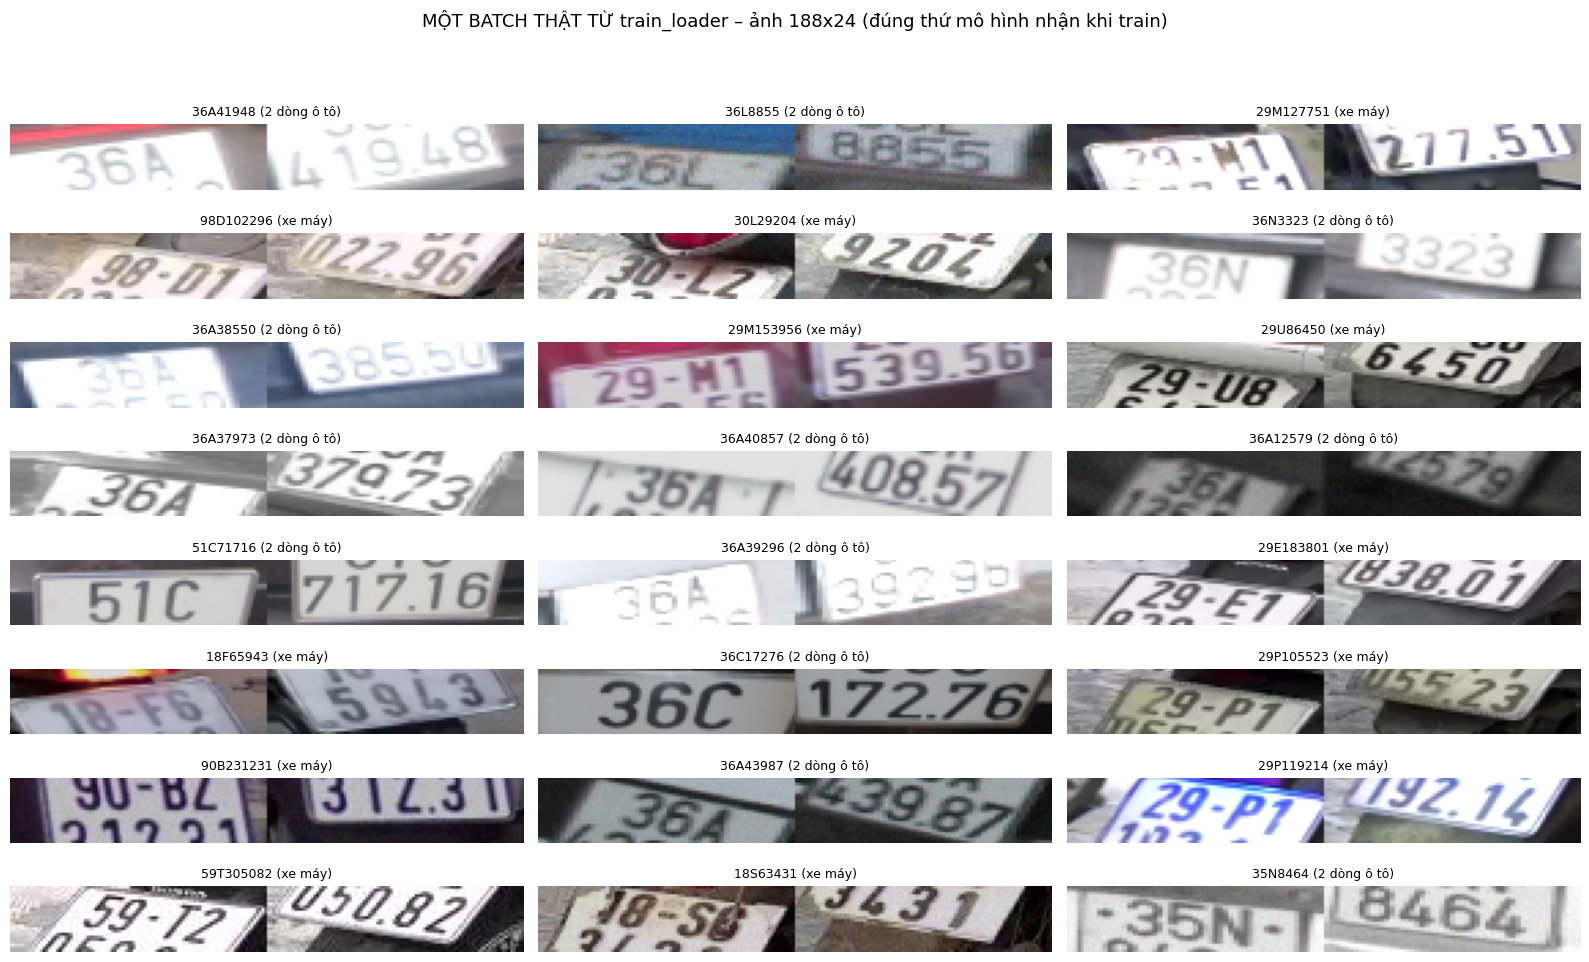

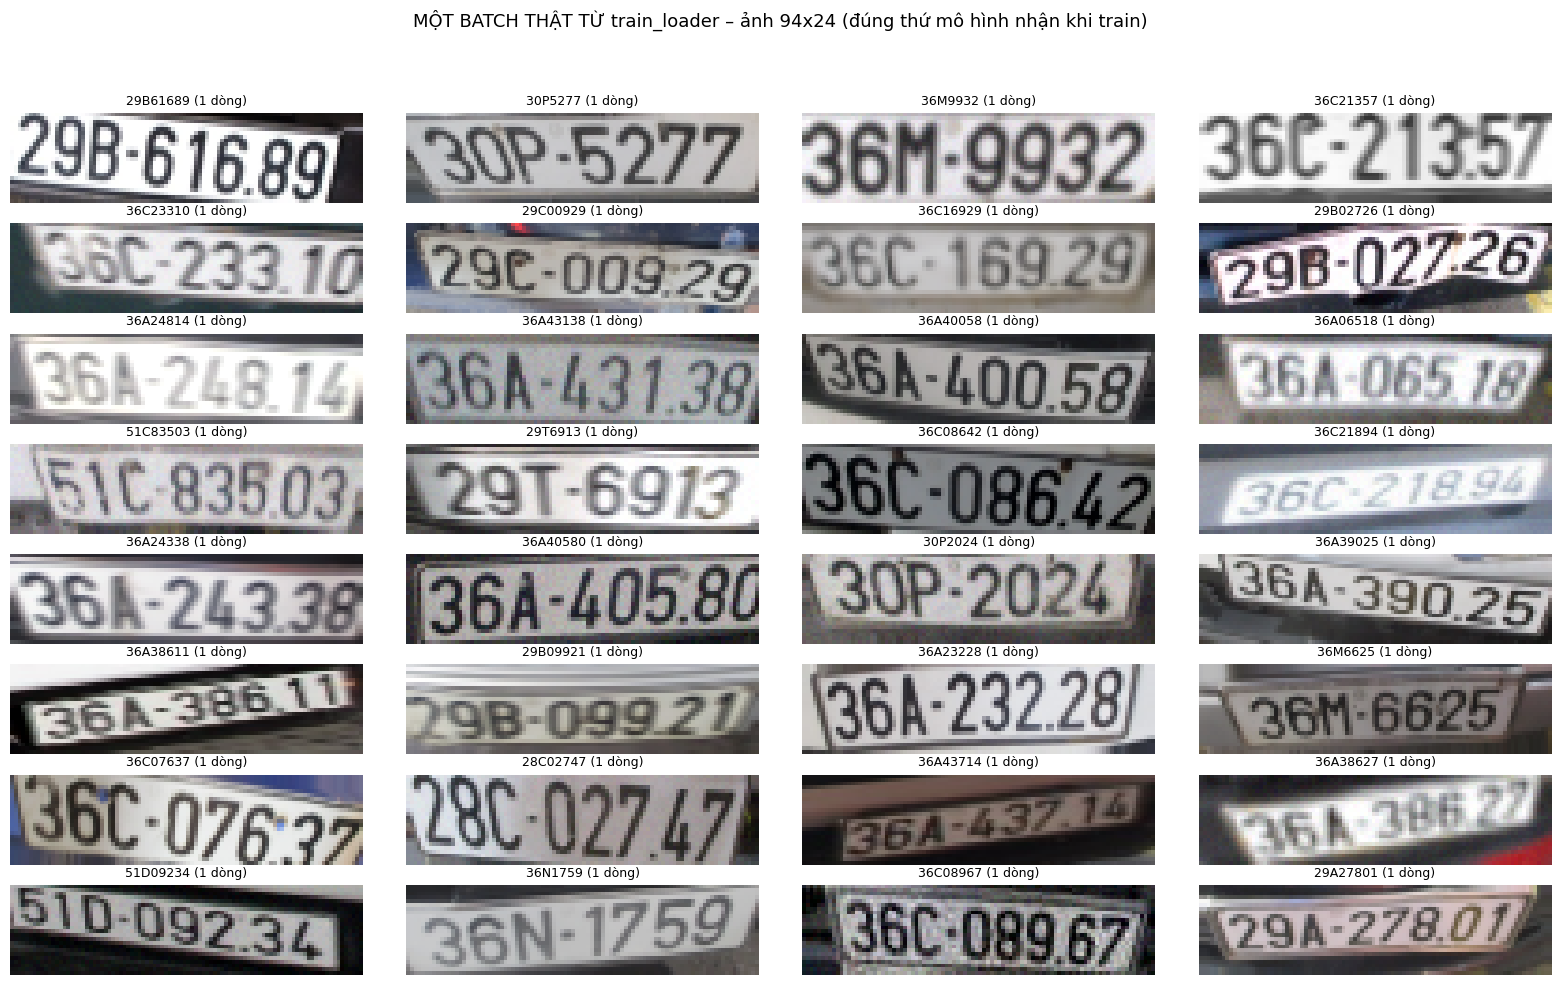

-> Val: 5569 ảnh (2854 ảnh 3x24x94, 2715 ảnh 3x24x188), đúng kích thước theo loại biển | ảnh gần như trơn: 1 (0.02%)
-> Test: 5524 ảnh (2901 ảnh 3x24x94, 2623 ảnh 3x24x188), đúng kích thước theo loại biển | ảnh gần như trơn: 0 (0.00%)


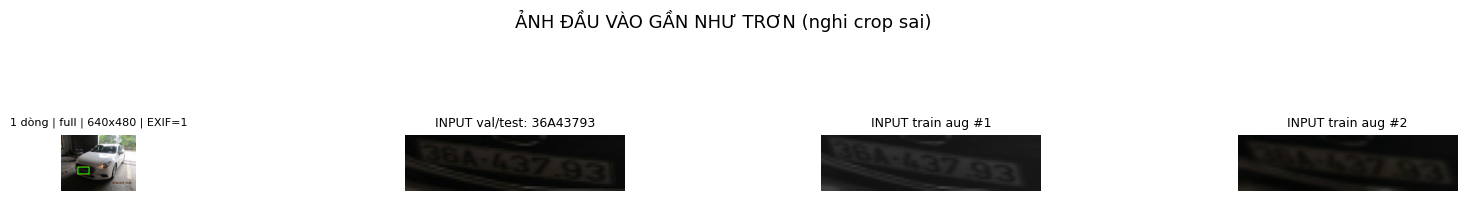

-> TIỀN XỬ LÝ ĐẠT YÊU CẦU, có thể bắt đầu huấn luyện.


In [9]:
def tensor_to_bgr(t):
    return np.clip(t.numpy().transpose(1, 2, 0) / 0.0078125 + 127.5, 0, 255).astype(np.uint8)

shown = set()
for imgs, _, _, labels, idxs in train_loader:   # in 1 batch ảnh 94 và 1 batch ảnh 188
    width = imgs.shape[-1]
    if width in shown:
        continue
    shown.add(width)
    cols = 4 if width == IMG_W else 3
    fig, axes = plt.subplots(8, cols, figsize=(16, 10), squeeze=False)
    for k, a in enumerate(axes.flat):
        a.axis("off")
        if k < len(labels):
            a.imshow(bgr2rgb(tensor_to_bgr(imgs[k])))
            a.set_title(f"{labels[k]} ({train_samples[idxs[k]]['group']})", fontsize=9)
    add_title(fig, f"MỘT BATCH THẬT TỪ train_loader – ảnh {width}x{IMG_H} (đúng thứ mô hình nhận khi train)")
    plt.show()
    if len(shown) == 2:
        break

def scan_loader(loader, samples, name, std_thr=0.08):
    n, flat, n_w = 0, [], Counter()
    for imgs, _, _, labels, idxs in loader:
        widths = {input_width(samples[i]) for i in idxs}
        assert len(widths) == 1, "Một batch chứa ảnh khác chiều rộng"
        assert imgs.shape[1:] == (3, IMG_H, widths.pop()), f"Sai kích thước đầu vào: {tuple(imgs.shape)}"
        assert torch.isfinite(imgs).all(), "Đầu vào có NaN/Inf"
        n += len(labels)
        n_w[imgs.shape[-1]] += len(labels)
        stds = imgs.flatten(1).std(1).tolist()
        flat += [samples[i] for i, sd in zip(idxs, stds) if sd < std_thr]
    w_str = ", ".join(f"{c} ảnh 3x{IMG_H}x{w}" for w, c in sorted(n_w.items()))
    print(f"-> {name}: {n} ảnh ({w_str}), đúng kích thước theo loại biển | ảnh gần như trơn: {len(flat)} ({100 * len(flat) / max(1, n):.2f}%)")
    return n, flat

n_val, flat_val = scan_loader(val_loader, val_samples, "Val")
n_test, flat_test = scan_loader(test_loader, test_samples, "Test")
flat_all = flat_val + flat_test
preview_samples(flat_all, "ẢNH ĐẦU VÀO GẦN NHƯ TRƠN (nghi crop sai)", n=8)
if len(flat_all) > 0.01 * (n_val + n_test):
    raise RuntimeError("Hơn 1% ảnh đầu vào bị trơn. Hãy xem hình phía trên và sửa tiền xử lý trước khi train!")
print("-> TIỀN XỬ LÝ ĐẠT YÊU CẦU, có thể bắt đầu huấn luyện.")

### 8. Tải Trọng Số Pre-trained Gốc Của Tác Giả (sirius-ai)

In [10]:
if not os.path.exists(AUTHOR_WEIGHTS):
    print("Đang tải Final_LPRNet_model.pth chính thức...")
    !git clone -q --depth 1 https://github.com/sirius-ai/LPRNet_Pytorch.git /content/LPRNet_Pytorch
    shutil.copy("/content/LPRNet_Pytorch/weights/Final_LPRNet_model.pth", AUTHOR_WEIGHTS)
print(f"-> Trọng số tác giả: {AUTHOR_WEIGHTS} ({os.path.getsize(AUTHOR_WEIGHTS) / 1e6:.2f} MB)")

if WEIGHTS_MODE == "resume":
    if os.path.exists(LAST_PATH):
        print(f"-> ĐÃ CHỌN: TRAIN TIẾP từ {LAST_PATH}")
    else:
        raise FileNotFoundError(f"Chưa có {LAST_PATH}. Hãy đặt WEIGHTS_MODE = 'author' để train từ đầu.")
elif WEIGHTS_MODE == "v2":
    if not os.path.exists(V2_BEST_PATH):
        raise FileNotFoundError(f"Chưa có {V2_BEST_PATH}. Hãy đặt WEIGHTS_MODE = 'author'.")
    print(f"-> ĐÃ CHỌN: KHỞI TẠO TỪ CHECKPOINT v2 ({V2_BEST_PATH})")
else:
    print("-> ĐÃ CHỌN: TRANSFER LEARNING TỪ TRỌNG SỐ TÁC GIẢ.")

Đang tải Final_LPRNet_model.pth chính thức...
-> Trọng số tác giả: /content/weights/Final_LPRNet_model.pth (1.81 MB)
-> ĐÃ CHỌN: TRANSFER LEARNING TỪ TRỌNG SỐ TÁC GIẢ.


### 9. Kiến Trúc LPRNet Gốc (Zherzdev & Gruzdev, 2018; bản PyTorch sirius-ai) & Chuyển Giao 100% Trọng Số
- Kiến trúc giữ **đúng từng tầng** như bản gốc, nên tên và kích thước tensor khớp 100% với `Final_LPRNet_model.pth`.
- **Global Context:** đặc trưng ở các tầng 2, 6, 13, 22 được pooling về cùng kích thước 4×T, chuẩn hóa, ghép kênh rồi qua conv 1×1.
- **Ảnh rộng 188 (biển 2 dòng):** toàn bộ backbone là tích chập nên chạy được với mọi chiều rộng. Riêng 3 nhánh Global Context vẫn dùng avgpool gốc (cùng kích thước cửa sổ), sau đó được nội suy theo chiều ngang về đúng T = 42. Với ảnh 94 không cần nội suy (T = 18), nên mô hình **giống hệt bản gốc** và transfer vẫn đúng 100%.
- Bản gốc chuẩn hóa global context bằng trung bình trên **cả batch**. Ở đây chuẩn hóa **theo từng ảnh** để kết quả không phụ thuộc batch size (khi suy luận batch = 1).
- **Chuyển giao tầng phân loại theo ký tự:** mô hình gốc có 68 lớp (31 chữ Hán, 0–9, A–Z, blank `-`). 3 tensor phụ thuộc số lớp (`backbone.20`, `backbone.21`, `container.0`) được **lấy đúng các hàng/cột của 30 ký tự VN và blank**. Nhờ vậy cả tầng phân loại cũng được kế thừa, không phải khởi tạo ngẫu nhiên.

In [11]:
SIRIUS_CHARS = [
    '京', '沪', '津', '渝', '冀', '晋', '蒙', '辽', '吉', '黑',
    '苏', '浙', '皖', '闽', '赣', '鲁', '豫', '鄂', '湘', '粤',
    '桂', '琼', '川', '贵', '云', '藏', '陕', '甘', '青', '宁',
    '新',
    '0', '1', '2', '3', '4', '5', '6', '7', '8', '9',
    'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'J', 'K',
    'L', 'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'U', 'V',
    'W', 'X', 'Y', 'Z', 'I', 'O', '-'
]

class small_basic_block(nn.Module):
    def __init__(self, ch_in, ch_out):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(ch_in, ch_out // 4, kernel_size=1),
            nn.ReLU(),
            nn.Conv2d(ch_out // 4, ch_out // 4, kernel_size=(3, 1), padding=(1, 0)),
            nn.ReLU(),
            nn.Conv2d(ch_out // 4, ch_out // 4, kernel_size=(1, 3), padding=(0, 1)),
            nn.ReLU(),
            nn.Conv2d(ch_out // 4, ch_out, kernel_size=1),
        )

    def forward(self, x):
        return self.block(x)

class LPRNet(nn.Module):
    KEEP_IDX = (2, 6, 13, 22)   # các tầng lấy đặc trưng cho Global Context

    def __init__(self, class_num=NUM_CLASSES, dropout_rate=0.5):
        super().__init__()
        self.class_num = class_num
        self.backbone = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, stride=1),                       # 0
            nn.BatchNorm2d(64),
            nn.ReLU(),                                                       # 2  *
            nn.MaxPool3d(kernel_size=(1, 3, 3), stride=(1, 1, 1)),
            small_basic_block(64, 128),                                      # 4
            nn.BatchNorm2d(128),
            nn.ReLU(),                                                       # 6  *
            nn.MaxPool3d(kernel_size=(1, 3, 3), stride=(2, 1, 2)),
            small_basic_block(64, 256),                                      # 8
            nn.BatchNorm2d(256),
            nn.ReLU(),                                                       # 10
            small_basic_block(256, 256),                                     # 11
            nn.BatchNorm2d(256),
            nn.ReLU(),                                                       # 13 *
            nn.MaxPool3d(kernel_size=(1, 3, 3), stride=(4, 1, 2)),
            nn.Dropout(dropout_rate),
            nn.Conv2d(64, 256, kernel_size=(1, 4), stride=1),                # 16
            nn.BatchNorm2d(256),
            nn.ReLU(),                                                       # 18
            nn.Dropout(dropout_rate),
            nn.Conv2d(256, class_num, kernel_size=(13, 1), stride=1),        # 20
            nn.BatchNorm2d(class_num),
            nn.ReLU(),                                                       # 22 *
        )
        self.container = nn.Sequential(
            nn.Conv2d(448 + class_num, class_num, kernel_size=(1, 1), stride=(1, 1)),
        )

    def forward(self, x):
        keep = []
        for i, layer in enumerate(self.backbone.children()):
            x = layer(x)
            if i in self.KEEP_IDX:
                keep.append(x)
        out_hw = keep[-1].shape[-2:]   # (4, T): T = 18 với ảnh rộng 94, T = 42 với ảnh rộng 188
        context = []
        for i, f in enumerate(keep):
            if i in (0, 1):
                f = F.avg_pool2d(f, kernel_size=5, stride=5)
            elif i == 2:
                f = F.avg_pool2d(f, kernel_size=(4, 10), stride=(4, 2))
            if f.shape[-2:] != out_hw:   # chỉ xảy ra khi ảnh khác rộng 94
                f = F.interpolate(f, size=out_hw, mode="bilinear", align_corners=False)
            f = f / f.pow(2).mean(dim=(1, 2, 3), keepdim=True).clamp_min(1e-6)
            context.append(f)
        x = self.container(torch.cat(context, 1))
        logits = x.mean(dim=2)            # [B, C, T]
        return logits.permute(2, 0, 1)    # [T, B, C] cho CTC

HEAD_PREFIXES = ("backbone.20.", "backbone.21.", "container.")   # các tensor phụ thuộc số lớp
CTX_CH = 64 + 128 + 256

def transfer_author_weights(model, path):
    sd = torch.load(path, map_location="cpu")
    sd = {k.replace("module.", ""): v for k, v in sd.items()}
    n_src = sd["container.0.weight"].shape[0]
    assert n_src == len(SIRIUS_CHARS), f"File tác giả có {n_src} lớp, khác {len(SIRIUS_CHARS)} lớp mong đợi"
    idx = torch.tensor([SIRIUS_CHARS.index(c) for c in CHARS] + [SIRIUS_CHARS.index("-")])
    new_sd = {}
    for k, v in sd.items():
        if k == "container.0.weight":   # [68, 448+68, 1, 1] -> [31, 448+31, 1, 1]
            v = torch.cat([v[:, :CTX_CH], v[:, CTX_CH:][:, idx]], dim=1)[idx]
        elif k.startswith(HEAD_PREFIXES) and v.ndim >= 1 and v.shape[0] == n_src:
            v = v[idx]
        new_sd[k] = v
    model.load_state_dict(new_sd, strict=True)
    print(f"-> ĐÃ CHUYỂN GIAO {len(new_sd)}/{len(model.state_dict())} TENSOR (100%) TỪ FILE TÁC GIẢ")
    print(f"   Tầng phân loại: lấy {len(idx)} / {n_src} lớp gốc theo ký tự (30 ký tự VN + blank)")

model = LPRNet(NUM_CLASSES, DROPOUT).to(device)
if WEIGHTS_MODE == "author":
    transfer_author_weights(model, AUTHOR_WEIGHTS)
elif WEIGHTS_MODE == "v2":
    model.load_state_dict(torch.load(V2_BEST_PATH, map_location=device))
    print(f"-> ĐÃ NẠP CHECKPOINT v2: {V2_BEST_PATH} (cùng kiến trúc, chỉ khác cách đưa biển 2 dòng vào)")

model.eval()
with torch.no_grad():
    for w in (IMG_W, IMG_W2):
        out = model(torch.zeros(2, 3, IMG_H, w, device=device))
        assert out.shape == (T_STEPS[w], 2, NUM_CLASSES), f"Đầu ra sai kích thước: {tuple(out.shape)}"
        print(f"-> Ảnh {w}x{IMG_H}: đầu ra (T, B, C) = {tuple(out.shape)}")
print(f"-> Số tham số: {sum(p.numel() for p in model.parameters()) / 1e3:.1f}K")

-> ĐÃ CHUYỂN GIAO 62/62 TENSOR (100%) TỪ FILE TÁC GIẢ
   Tầng phân loại: lấy 31 / 68 lớp gốc theo ký tự (30 ký tự VN + blank)
-> Ảnh 94x24: đầu ra (T, B, C) = (18, 2, 31)
-> Ảnh 188x24: đầu ra (T, B, C) = (42, 2, 31)
-> Số tham số: 303.5K


### 10. Giải Mã CTC, Hậu Xử Lý Định Dạng Biển VN & Đánh Giá Theo Từng Nhóm
`fix_vn_plate` sửa các cặp ký tự dễ nhầm theo vị trí (`8↔B`, `0↔D`, `5↔S`, `2↔Z`, `6↔G`, `4↔A`): 2 ký tự đầu và 4 ký tự cuối luôn là số, ký tự thứ 3 luôn là chữ. Hàm chỉ sửa khi dự đoán gốc **sai định dạng** và bản sửa **đúng định dạng**. Vì mọi nhãn đều đúng định dạng (đã lọc ở Bước 4), hàm **không bao giờ làm sai một dự đoán vốn đúng**, nên Seq Acc chỉ có thể tăng. Kết quả **được báo cáo riêng** (thô và có hậu xử lý) để minh bạch.

In [12]:
TO_DIGIT  = {"B": "8", "D": "0", "S": "5", "Z": "2", "G": "6", "A": "4"}
TO_LETTER = {v: k for k, v in TO_DIGIT.items()}

def decode_greedy(logits):
    best_paths = logits.argmax(dim=2).transpose(0, 1).cpu().numpy()
    decoded = []
    for path in best_paths:
        res, prev = [], None
        for idx in path:
            if idx != prev and idx != BLANK_IDX:
                res.append(CHARS[idx])
            prev = idx
        decoded.append("".join(res))
    return decoded

def fix_vn_plate(p):
    # Chỉ sửa khi dự đoán chưa đúng định dạng VN VÀ bản sửa đúng định dạng (tránh làm hỏng dự đoán bị thiếu ký tự)
    if len(p) < 7 or VN_PLATE_RE.match(p):
        return p
    c = list(p)
    for i in (0, 1):
        c[i] = TO_DIGIT.get(c[i], c[i])
    c[2] = TO_LETTER.get(c[2], c[2])
    for i in range(len(c) - 4, len(c)):
        c[i] = TO_DIGIT.get(c[i], c[i])
    fixed = "".join(c)
    return fixed if VN_PLATE_RE.match(fixed) else p

@torch.no_grad()
def predict(net, loader):
    net.eval()
    records = []
    for imgs, _, _, labels, idxs in loader:
        preds = decode_greedy(net(imgs.to(device, non_blocking=True)))
        records.extend(zip(idxs, labels, preds))
    return records

def summarize(records, samples, fix=False):
    acc = {k: [0, 0, 0, 0] for k in GROUPS + ["TỔNG"]}   # n, đúng, edit distance, số ký tự
    for i, gt, p in records:
        if fix:
            p = fix_vn_plate(p)
        for k in (samples[i]["group"], "TỔNG"):
            a = acc[k]
            a[0] += 1
            a[1] += p == gt
            a[2] += editdistance.eval(p, gt)
            a[3] += len(gt)
    return {k: {"n": n, "acc": 100 * c / n, "cer": e / ch} for k, (n, c, e, ch) in acc.items() if n}

def print_summary(res, title):
    print("=" * 56)
    print(title)
    print("-" * 56)
    print(f"{'Nhóm':14s}{'n':>8s}{'Seq Acc':>14s}{'CER':>12s}")
    for k, r in res.items():
        print(f"{k:14s}{r['n']:8d}{r['acc']:13.2f}%{r['cer']:12.4f}")
    print("=" * 56)

### 11. Đánh Giá Zero-shot (Trọng Số Tác Giả, Chưa Train Trên Dữ Liệu VN)
Dùng làm mốc so sánh cho báo cáo (TN-OCR 1): mô hình chỉ học biển Trung Quốc thì đọc biển VN được bao nhiêu. Nếu `WEIGHTS_MODE = "v2"` thì ô này đo checkpoint v2 khi đổi sang đầu vào 188 (biển 2 dòng sẽ kém vì v2 chưa từng thấy ảnh rộng 188).

In [13]:
if WEIGHTS_MODE in ("author", "v2"):
    zs_records = predict(model, val_loader)
    zs_name = "trọng số tác giả" if WEIGHTS_MODE == "author" else "checkpoint v2 với đầu vào 188 cho biển 2 dòng"
    print_summary(summarize(zs_records, val_samples), f"TRƯỚC KHI TRAIN trên Val ({zs_name})")
    for i, gt, p in zs_records[:8]:
        print(f"   GT {gt:10s} -> {p}")

TRƯỚC KHI TRAIN trên Val (trọng số tác giả)
--------------------------------------------------------
Nhóm                 n       Seq Acc         CER
1 dòng            2854        10.69%      0.2855
2 dòng ô tô       1880         0.05%      0.7177
xe máy             835         0.00%      0.8316
TỔNG              5569         5.49%      0.5185
   GT 11C02974   -> 00299
   GT 14A08480   -> 04A08480
   GT 14A10692   -> 04A0892
   GT 14M8726    -> MM87266
   GT 14M9675    -> AM8675
   GT 14N7269    -> 6DN726S9
   GT 14P3910    -> 7PP3070
   GT 15A28464   -> 05A284N64


### 12. Huấn Luyện 2 Pha (Tự Lưu Drive Mỗi Epoch, Train Tiếp Được Khi Bị Ngắt)
- **Pha 1 (Frozen):** đóng băng backbone (kể cả thống kê BatchNorm), chỉ train 3 tầng phụ thuộc số lớp với Adam 1e-3.
- **Pha 2 (Fine-tune):** mở toàn mạng, AdamW + OneCycleLR (khởi động 10% rồi giảm dần). Scheduler bước theo từng batch.
- Checkpoint tốt nhất được chọn theo **Val Seq Acc** (bằng nhau thì xét CER thấp hơn). Checkpoint cuối lưu mỗi epoch để train tiếp.


--- BẮT ĐẦU HUẤN LUYỆN: 3 epoch Frozen + 80 epoch Fine-tune ---
Epoch [001/83] frozen   | lr 1.00e-03 | Loss 4.7412 | Val Acc 26.52% | CER 0.3607 | 1 dòng: 51.2% | 2 dòng ô tô: 0.6% | xe máy: 0.5% | 17s
   [LƯU CHECKPOINT TỐT NHẤT] /content/drive/MyDrive/TGMT/lprnet_v3/best_lprnet_vn_v3.pth
Epoch [002/83] frozen   | lr 1.00e-03 | Loss 2.9467 | Val Acc 27.76% | CER 0.2748 | 1 dòng: 49.8% | 2 dòng ô tô: 6.1% | xe máy: 1.3% | 17s
   [LƯU CHECKPOINT TỐT NHẤT] /content/drive/MyDrive/TGMT/lprnet_v3/best_lprnet_vn_v3.pth
Epoch [003/83] frozen   | lr 1.00e-03 | Loss 2.2249 | Val Acc 34.05% | CER 0.2575 | 1 dòng: 60.0% | 2 dòng ô tô: 9.3% | xe máy: 1.2% | 17s
   [LƯU CHECKPOINT TỐT NHẤT] /content/drive/MyDrive/TGMT/lprnet_v3/best_lprnet_vn_v3.pth

-> CHUYỂN PHA 2: Mở đóng băng toàn bộ mạng, AdamW + OneCycleLR
Epoch [004/83] finetune | lr 7.66e-05 | Loss 28.3434 | Val Acc 0.00% | CER 1.1495 | 1 dòng: 0.0% | 2 dòng ô tô: 0.0% | xe máy: 0.0% | 17s
Epoch [005/83] finetune | lr 1.81e-04 | Loss 12.7

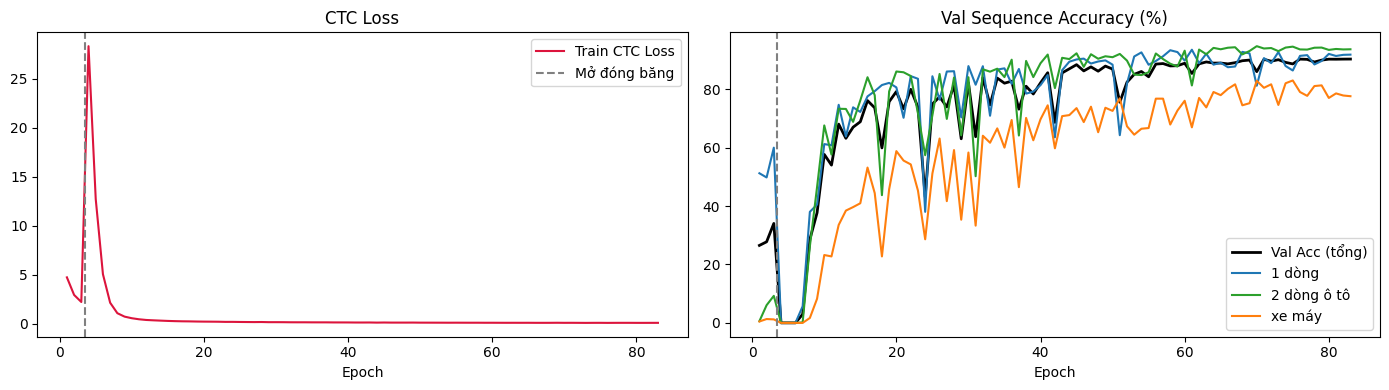

-> Đã lưu biểu đồ và lịch sử huấn luyện vào /content/drive/MyDrive/TGMT/lprnet_v3


In [14]:
criterion = nn.CTCLoss(blank=BLANK_IDX, zero_infinity=True)
TOTAL_EPOCHS = FROZEN_EPOCHS + FINETUNE_EPOCHS
steps_per_epoch = len(train_loader)

def phase_of(epoch):
    return "frozen" if epoch <= FROZEN_EPOCHS else "finetune"

def setup_phase(phase):
    for n, p in model.named_parameters():
        p.requires_grad = phase == "finetune" or n.startswith(HEAD_PREFIXES)
    if phase == "frozen":
        return optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LR_HEAD), None
    opt = optim.AdamW(model.parameters(), lr=MAX_LR, weight_decay=WEIGHT_DECAY)
    sch = optim.lr_scheduler.OneCycleLR(opt, max_lr=MAX_LR, total_steps=FINETUNE_EPOCHS * steps_per_epoch, pct_start=0.1)
    return opt, sch

def set_train_mode(phase):
    model.train()
    if phase == "frozen":   # giữ nguyên thống kê BN của các tầng bị đóng băng
        for name, m in model.backbone.named_children():
            if isinstance(m, nn.BatchNorm2d) and not f"backbone.{name}.".startswith(HEAD_PREFIXES):
                m.eval()

def save_to_drive(obj, path):
    local = os.path.join(LOCAL_DIR, os.path.basename(path))
    torch.save(obj, local)
    shutil.copy(local, path)

start_epoch, best_acc, best_cer, history, ckpt = 1, -1.0, 1e9, [], None
if WEIGHTS_MODE == "resume":
    ckpt = torch.load(LAST_PATH, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model"])
    start_epoch = ckpt["epoch"] + 1
    best_acc, best_cer, history = ckpt["best_acc"], ckpt["best_cer"], ckpt["history"]
    print(f"-> Train tiếp từ epoch {start_epoch} (best Val Acc hiện tại {best_acc:.2f}%)")

phase = phase_of(start_epoch)
optimizer, scheduler = setup_phase(phase)
if ckpt is not None and ckpt["phase"] == phase:
    optimizer.load_state_dict(ckpt["optimizer"])
    if scheduler is not None and ckpt["scheduler"] is not None:
        scheduler.load_state_dict(ckpt["scheduler"])

try:
    print()
    print(f"--- BẮT ĐẦU HUẤN LUYỆN: {FROZEN_EPOCHS} epoch Frozen + {FINETUNE_EPOCHS} epoch Fine-tune ---")
    for epoch in range(start_epoch, TOTAL_EPOCHS + 1):
        if phase_of(epoch) != phase:
            phase = phase_of(epoch)
            optimizer, scheduler = setup_phase(phase)
            print()
            print("-> CHUYỂN PHA 2: Mở đóng băng toàn bộ mạng, AdamW + OneCycleLR")

        set_train_mode(phase)
        t0, running_loss = time.time(), 0.0
        for imgs, targets, target_lengths, _, _ in train_loader:
            imgs, targets = imgs.to(device, non_blocking=True), targets.to(device)
            logits = model(imgs)
            T, B, _ = logits.size()
            input_lengths = torch.full((B,), T, dtype=torch.long)
            loss = criterion(logits.log_softmax(2), targets, input_lengths, target_lengths)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            if scheduler is not None:
                scheduler.step()
            running_loss += loss.item()

        res = summarize(predict(model, val_loader), val_samples)
        epoch_loss = running_loss / max(1, steps_per_epoch)
        lr_now = optimizer.param_groups[0]["lr"]
        history.append({"epoch": epoch, "phase": phase, "loss": epoch_loss, "lr": lr_now,
                        "val_acc": res["TỔNG"]["acc"], "val_cer": res["TỔNG"]["cer"],
                        **{f"acc_{g}": res[g]["acc"] for g in GROUPS if g in res}})
        group_str = " | ".join(f"{g}: {res[g]['acc']:.1f}%" for g in GROUPS if g in res)
        print(f"Epoch [{epoch:03d}/{TOTAL_EPOCHS}] {phase:8s} | lr {lr_now:.2e} | Loss {epoch_loss:.4f} | "
              f"Val Acc {res['TỔNG']['acc']:.2f}% | CER {res['TỔNG']['cer']:.4f} | {group_str} | {time.time() - t0:.0f}s")

        acc_now, cer_now = res["TỔNG"]["acc"], res["TỔNG"]["cer"]
        if acc_now > best_acc or (acc_now == best_acc and cer_now < best_cer):
            best_acc, best_cer = acc_now, cer_now
            save_to_drive(model.state_dict(), BEST_PATH)
            print(f"   [LƯU CHECKPOINT TỐT NHẤT] {BEST_PATH}")
        save_to_drive({"epoch": epoch, "phase": phase, "model": model.state_dict(),
                       "optimizer": optimizer.state_dict(),
                       "scheduler": scheduler.state_dict() if scheduler is not None else None,
                       "best_acc": best_acc, "best_cer": best_cer, "history": history}, LAST_PATH)

    print()
    print(f"-> Huấn luyện hoàn tất! Checkpoint tốt nhất: {BEST_PATH} (Val Acc {best_acc:.2f}%, CER {best_cer:.4f})")
    frozen_hist = [h for h in history if h["phase"] == "frozen"]
    if frozen_hist:
        print(f"-> TN-OCR 1: Frozen (hết pha 1) = {frozen_hist[-1]['val_acc']:.2f}% | Fine-tuned (tốt nhất) = {best_acc:.2f}%")

    with open(f"{SAVE_DIR}/train_history.json", "w", encoding="utf-8") as f:
        json.dump(history, f, ensure_ascii=False, indent=1)
    ep = [h["epoch"] for h in history]
    plt.figure(figsize=(14, 4))
    plt.subplot(1, 2, 1)
    plt.plot(ep, [h["loss"] for h in history], color="crimson", label="Train CTC Loss")
    plt.axvline(FROZEN_EPOCHS + 0.5, color="gray", ls="--", label="Mở đóng băng")
    plt.title("CTC Loss"); plt.xlabel("Epoch"); plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(ep, [h["val_acc"] for h in history], color="black", lw=2, label="Val Acc (tổng)")
    for g, c in zip(GROUPS, ["tab:blue", "tab:green", "tab:orange"]):
        plt.plot(ep, [h.get(f"acc_{g}", np.nan) for h in history], color=c, label=g)
    plt.axvline(FROZEN_EPOCHS + 0.5, color="gray", ls="--")
    plt.title("Val Sequence Accuracy (%)"); plt.xlabel("Epoch"); plt.legend()
    plt.tight_layout()
    plt.savefig(f"{SAVE_DIR}/lprnet_v3_training_curves.png", dpi=300)
    plt.show()
    print(f"-> Đã lưu biểu đồ và lịch sử huấn luyện vào {SAVE_DIR}")

except KeyboardInterrupt:
    print()
    print(f"-> Đã dừng tay. Checkpoint cuối nằm ở {LAST_PATH}, đặt WEIGHTS_MODE = 'resume' để train tiếp.")
except Exception:
    print()
    print("PHÁT HIỆN LỖI TRONG QUÁ TRÌNH HUẤN LUYỆN:")
    traceback.print_exc()
    crash_path = f"{SAVE_DIR}/emergency_lprnet_vn_v3.pth"
    torch.save(model.state_dict(), crash_path)
    print(f"-> Đã lưu checkpoint khẩn cấp: {crash_path}")
    idle_shutdown_timer()

### 13. Đánh Giá Chính Thức Trên Tập Test Độc Lập (Số Liệu Cho Báo Cáo)

In [15]:
best_model = LPRNet(NUM_CLASSES, DROPOUT).to(device)
best_model.load_state_dict(torch.load(BEST_PATH, map_location=device))
print(f"-> Đã nạp checkpoint tốt nhất: {BEST_PATH}")

test_records = predict(best_model, test_loader)
res_raw = summarize(test_records, test_samples)
res_fix = summarize(test_records, test_samples, fix=True)
print_summary(res_raw, "KẾT QUẢ TEST – LPRNet (giải mã greedy, chưa hậu xử lý)")
print_summary(res_fix, "KẾT QUẢ TEST – LPRNet + hậu xử lý định dạng biển VN")

import csv
with open(f"{SAVE_DIR}/test_predictions.csv", "w", newline="", encoding="utf-8-sig") as f:
    w = csv.writer(f)
    w.writerow(["img_path", "group", "gt", "pred", "pred_fixed", "correct", "correct_fixed"])
    for i, gt, p in test_records:
        s = test_samples[i]
        w.writerow([s["img_path"], s["group"], gt, p, fix_vn_plate(p), int(p == gt), int(fix_vn_plate(p) == gt)])
with open(f"{SAVE_DIR}/test_results.json", "w", encoding="utf-8") as f:
    json.dump({"raw": res_raw, "fixed": res_fix}, f, ensure_ascii=False, indent=1)
print(f"-> Đã lưu toàn bộ dự đoán Test: {SAVE_DIR}/test_predictions.csv")
print("👉 Điền Sequence Accuracy và CER (tổng và từng nhóm) vào bảng thực nghiệm Chương 3!")

-> Đã nạp checkpoint tốt nhất: /content/drive/MyDrive/TGMT/lprnet_v3/best_lprnet_vn_v3.pth
KẾT QUẢ TEST – LPRNet (giải mã greedy, chưa hậu xử lý)
--------------------------------------------------------
Nhóm                 n       Seq Acc         CER
1 dòng            2901        91.11%      0.0142
2 dòng ô tô       1830        92.84%      0.0128
xe máy             793        81.59%      0.0292
TỔNG              5524        90.31%      0.0161
KẾT QUẢ TEST – LPRNet + hậu xử lý định dạng biển VN
--------------------------------------------------------
Nhóm                 n       Seq Acc         CER
1 dòng            2901        91.14%      0.0144
2 dòng ô tô       1830        92.84%      0.0133
xe máy             793        82.09%      0.0293
TỔNG              5524        90.41%      0.0164
-> Đã lưu toàn bộ dự đoán Test: /content/drive/MyDrive/TGMT/lprnet_v3/test_predictions.csv
👉 Điền Sequence Accuracy và CER (tổng và từng nhóm) vào bảng thực nghiệm Chương 3!


### 14. Phân Tích & In Ảnh Các Dự Đoán Lỗi Trên Tập Test
Mỗi hàng gồm ảnh gốc (khung bbox) và ảnh đầu vào mô hình, kèm `GT → dự đoán`. Hình được lưu vào Drive để đưa vào báo cáo.

In [16]:
import difflib

errors = [(i, gt, p) for i, gt, p in test_records if p != gt]
print(f"-> Tổng số mẫu sai trên Test: {len(errors)} / {len(test_records)}")

def error_kind(gt, p):
    d = len(p) - len(gt)
    if d <= -3:
        return "hỏng nặng (thiếu ≥3)"
    if d == 0:
        return "thay thế"
    return "thiếu 1-2" if d < 0 else "thừa"

kinds = Counter((test_samples[i]["group"], error_kind(gt, p)) for i, gt, p in errors)
kind_names = ["thay thế", "thiếu 1-2", "thừa", "hỏng nặng (thiếu ≥3)"]
print()
print(f"{'Nhóm':14s}" + "".join(f"{k:>22s}" for k in kind_names))
for g in GROUPS:
    print(f"{g:14s}" + "".join(f"{kinds[(g, k)]:22d}" for k in kind_names))

confusions = Counter()
for _, gt, p in errors:
    for op, a0, a1, b0, b1 in difflib.SequenceMatcher(None, gt, p, autojunk=False).get_opcodes():
        if op == "replace" and a1 - a0 == b1 - b0:
            confusions.update(f"{x}→{y}" for x, y in zip(gt[a0:a1], p[b0:b1]))
        elif op in ("delete", "replace"):
            confusions.update(f"{x}→∅" for x in gt[a0:a1])
        if op == "insert" or (op == "replace" and a1 - a0 != b1 - b0):
            confusions.update(f"∅→{y}" for y in p[b0:b1])
print()
print("20 cặp nhầm lẫn ký tự phổ biến nhất (∅ = thiếu / thừa ký tự):")
print("   " + " | ".join(f"{k}: {v}" for k, v in confusions.most_common(20)))

GROUP_SLUG = {"1 dòng": "1_dong", "2 dòng ô tô": "2_dong_oto", "xe máy": "xe_may"}

def show_errors(errs, title, n=16, seed=0, save_name=None):
    if not errs:
        print(f"(Không có lỗi: {title})")
        return
    picks = random.Random(seed).sample(errs, min(n, len(errs)))
    fig, axes = plt.subplots(len(picks), 2, figsize=(12, 2.0 * len(picks)), squeeze=False,
                             gridspec_kw={"width_ratios": [1, 1.5]})
    for r, (i, gt, p) in enumerate(picks):
        s = test_samples[i]
        img = read_image(s["img_path"])
        axes[r, 0].imshow(full_with_boxes(s, img))
        axes[r, 0].set_title(os.path.basename(s["img_path"])[:45], fontsize=7)
        axes[r, 1].imshow(bgr2rgb(preprocess(img, s, is_train=False)))
        fx = fix_vn_plate(p)
        note = f"  | hậu xử lý: {fx}" + (" ✓" if fx == gt else "") if fx != p else ""
        axes[r, 1].set_title(f"GT {gt}  →  {p}{note}", fontsize=10, color="crimson")
        for a in axes[r]:
            a.axis("off")
    add_title(fig, title)
    if save_name:
        fig.savefig(f"{SAVE_DIR}/{save_name}", dpi=120)
    plt.show()

for g in GROUPS:
    g_err = [e for e in errors if test_samples[e[0]]["group"] == g]
    show_errors(g_err, f"LỖI DỰ ĐOÁN TRÊN TEST – {g} ({len(g_err)} mẫu sai)", save_name=f"test_errors_{GROUP_SLUG[g]}.png")
print(f"-> Đã lưu hình lỗi vào {SAVE_DIR}/test_errors_*.png")

Output hidden; open in https://colab.research.google.com to view.

### 15. Hàm Suy Luận Cho Pipeline YOLO → LPRNet
Khi chạy thực tế, không có nhãn 1 dòng/2 dòng. Hàm dưới đây đoán từ tỉ lệ rộng/cao của bbox YOLO (ngưỡng tìm ở Bước 4). Ô này cũng đo xem việc đoán đó làm giảm độ chính xác bao nhiêu so với dùng nhãn thật.

In [17]:
@torch.no_grad()
def recognize_plate(net, img_bgr, bbox, is_two_rows=None):
    """img_bgr: khung hình gốc (BGR), bbox: (xmin, ymin, xmax, ymax) từ YOLO."""
    xmin, ymin, xmax, ymax = map(int, bbox)
    if is_two_rows is None:
        is_two_rows = (xmax - xmin) / max(1, ymax - ymin) < TWO_ROW_RATIO_THR
    s = {"bbox": (xmin, ymin, xmax, ymax), "mode": "full", "is_two_rows": is_two_rows}
    x = to_tensor(preprocess(img_bgr, s, is_train=False))[None].to(device)
    net.eval()
    return fix_vn_plate(decode_greedy(net(x))[0])

check = [s for s in random.Random(0).sample(test_samples, min(1000, len(test_samples))) if s["mode"] == "full"]
hits_label = hits_guess = 0
for s in check:
    img = read_image(s["img_path"])
    hits_label += recognize_plate(best_model, img, s["bbox"], s["is_two_rows"]) == s["label"]
    hits_guess += recognize_plate(best_model, img, s["bbox"]) == s["label"]
print(f"-> {len(check)} ảnh Test: dùng nhãn 1/2 dòng thật = {100 * hits_label / max(1, len(check)):.2f}% | "
      f"đoán từ tỉ lệ bbox = {100 * hits_guess / max(1, len(check)):.2f}%")

-> 1000 ảnh Test: dùng nhãn 1/2 dòng thật = 90.50% | đoán từ tỉ lệ bbox = 88.50%


### 16. Đo Tốc Độ Thực Tế (Tiêu Chí Real-Time ≥ 20 FPS)

In [18]:
def bench_ms(net, x, iters=300, warmup=30):
    net.eval()
    with torch.no_grad():
        for _ in range(warmup):
            net(x)
        if x.is_cuda:
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(iters):
            net(x)
        if x.is_cuda:
            torch.cuda.synchronize()
    return (time.perf_counter() - t0) / iters * 1000

cpu_model = LPRNet(NUM_CLASSES, DROPOUT)
cpu_model.load_state_dict({k: v.cpu() for k, v in best_model.state_dict().items()})
for w, kind in ((IMG_W, "biển 1 dòng"), (IMG_W2, "biển 2 dòng")):
    lat_1 = bench_ms(best_model, torch.randn(1, 3, IMG_H, w, device=device))
    lat_32 = bench_ms(best_model, torch.randn(32, 3, IMG_H, w, device=device))
    lat_cpu = bench_ms(cpu_model, torch.randn(1, 3, IMG_H, w), iters=100, warmup=10)
    print(f"[{kind}, ảnh {w}x{IMG_H}]")
    print(f"   -> {device} | batch 1 : {lat_1:.2f} ms/biển  ({1000 / lat_1:.0f} FPS)")
    print(f"   -> {device} | batch 32: {lat_32 / 32:.3f} ms/biển ({32000 / lat_32:.0f} biển/giây)")
    print(f"   -> CPU    | batch 1 : {lat_cpu:.2f} ms/biển  ({1000 / lat_cpu:.0f} FPS)")

for two in (False, True):
    s0 = next((s for s in test_samples if s["mode"] == "full" and s["is_two_rows"] == two), None)
    if s0 is None:
        continue
    img0 = read_image(s0["img_path"])
    t0 = time.perf_counter()
    for _ in range(200):
        preprocess(img0, s0, is_train=False)
    pre_ms = (time.perf_counter() - t0) / 200 * 1000
    print(f"-> Tiền xử lý {'biển 2 dòng (crop + cắt đôi + resize)' if two else 'biển 1 dòng (crop + resize)'}, CPU: {pre_ms:.3f} ms/biển")
print(f"-> Kích thước file trọng số: {os.path.getsize(BEST_PATH) / 1e6:.2f} MB")

[biển 1 dòng, ảnh 94x24]
   -> cuda | batch 1 : 2.29 ms/biển  (437 FPS)
   -> cuda | batch 32: 0.074 ms/biển (13470 biển/giây)
   -> CPU    | batch 1 : 106.74 ms/biển  (9 FPS)
[biển 2 dòng, ảnh 188x24]
   -> cuda | batch 1 : 2.41 ms/biển  (416 FPS)
   -> cuda | batch 32: 0.254 ms/biển (3944 biển/giây)
   -> CPU    | batch 1 : 223.61 ms/biển  (4 FPS)
-> Tiền xử lý biển 1 dòng (crop + resize), CPU: 0.234 ms/biển
-> Tiền xử lý biển 2 dòng (crop + cắt đôi + resize), CPU: 0.145 ms/biển
-> Kích thước file trọng số: 1.24 MB


### 17. Tự Động Ngắt Phiên Colab (Bảo Vệ Compute Units)
Đặt ở cuối để *Run all* chạy xong hết rồi mới đếm ngược. Bấm Stop ở ô này để hủy.

In [19]:
idle_shutdown_timer()


⏰ KÍCH HOẠT HẸN GIỜ TỰ ĐỘNG NGẮT PHIÊN (IDLE SHUTDOWN): 30 PHÚT
👉 BẤM NÚT DỪNG (STOP Ở CELL NÀY) BẤT KỲ LÚC NÀO ĐỂ HỦY NGẮT VÀ TIẾP TỤC LÀM VIỆC!
⏳ Thời gian chờ còn lại trước khi ngắt GPU: 00 phút 04 giây...
-> ĐÃ HẾT 30 PHÚT! Đang giải phóng GPU Colab...
